# 전처리

코드를 작성하기 전에 아래 질문들을 먼저 생각해보고, 답을 마크다운으로 적어보세요.

- 결측치가 있는 컬럼은 무엇이고, 왜 결측치가 생겼을까? 삭제할지 / 어떤 값으로 채울지?
- 이상치(outlier)는 어떤 기준으로 정의할 것인가? (IQR, 도메인 지식 등)
- 범주형 변수(예: 계절, 날씨 상태 등)는 어떻게 인코딩할 것인가?
- 시간/날짜 컬럼에서 뽑아낼 수 있는 파생 변수는? (시간대, 요일, 주말 여부, 계절 등)
- train/validation 분리는 언제 할 것인가? 전처리보다 먼저? 이후? (데이터 누수 주의)


## 질문에 대한 답

- **결측치:** 기상 컬럼 전체에 결측이 있고, 특히 오존·미세먼지·초미세먼지에 많다(train 기준 76/90/117개). 측정소 장비 점검이나 통신 오류로 빠진 것으로 보인다. 모든 기상값이 비어 있는 행이 train에 2개, test에 1개 있다.
    - train의 전부 비어 있는 2행은 피처 정보가 없으므로 삭제한다. 그중 하나(id 1553)는 퇴근 시간인 18시에 대여량이 1로, 시스템 장애 같은 비정상 상황으로 보인다. 행 하나만 보고 판단하는 규칙이라 다른 행의 통계를 쓰지 않는다.
    - 나머지 결측은 **시간대(hour)별 중앙값**으로 채운다. 기온·습도·시정은 하루 중 시간에 따라 크게 달라서 전체 중앙값보다 정확하고, 중앙값은 미세먼지처럼 치우친 분포에도 덜 흔들린다.
    - 단, 이 대체는 **여기서 하지 않고 04의 Pipeline 안에서** 한다(`src/preprocessing.py`의 `HourMedianImputer`). 이유는 아래 "train/validation 분리" 참고.
    - 1시는 train/test 모두 오존·미세먼지·초미세먼지가 항상 비어 있다(측정이 안 되는 시간대로 보임). 근거 없는 값을 만들지 않도록 **결측으로 그대로 둔다.** 결측을 처리할 수 있는 트리 모델(XGBoost, sklearn RandomForest 등)은 그대로 쓸 수 있고, 선형 모델은 04에서 따로 처리해야 한다.
- **이상치:** IQR로 확인하되 지우지 않는다. 대여량이 큰 값은 퇴근 시간 피크라는 실제 수요이고, 미세먼지가 높은 값도 황사 같은 실제 날씨일 수 있다. 04에서 쓸 트리 계열 모델은 피처 이상치에 강하다.
- **범주형 인코딩:** 범주형은 `hour`뿐이다. 강수는 이미 0/1이다. 트리 모델에는 숫자 그대로 쓰고, 선형 모델을 쓸 때는 04의 파이프라인 안에서 원핫인코딩한다. 그래서 저장 파일에는 인코딩을 적용하지 않는다.
- **파생 변수:** 날짜가 없어 요일·주말·계절은 만들 수 없다. 01의 배경에서 정리한 출퇴근 시간대(7~9시, 17~19시)를 `is_peak`로 만든다.
- **train/validation 분리:** 결측 행 삭제 직후, 다른 분석을 하기 전에 train의 20%를 **holdout**으로 떼어 둔다(시간대 비율 유지). test는 정답이 없어 로컬에서 최종 성능을 잴 수 없고, 교차검증 점수는 모델 선택·튜닝에 반복해서 쓰이므로 낙관적으로 나온다. holdout은 이 노트북의 이상치 확인, 03 EDA, 04 모델 선택·튜닝에 전혀 쓰지 않고 05에서 최종 평가할 때 한 번만 쓴다. 나머지 80%(이하 train)로 04에서 교차검증을 한다. 데이터로부터 통계를 배우는 전처리(결측 대체, 인코딩)를 여기서 train 전체에 적용하면, 교차검증 때 검증 fold의 정보가 학습에 섞인다. 그래서 이 노트북에서는 **통계를 쓰지 않는 처리(행 삭제 규칙, `is_peak`)만** 하고, 통계를 쓰는 처리는 모두 04의 Pipeline에 넣어 fold마다 학습 fold로만 fit한다.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

sys.path.append('..')
from src.preprocessing import HourMedianImputer

RAW_DIR = '../data/raw/따릉이'
PROCESSED_DIR = '../data/processed'

train = pd.read_csv(f'{RAW_DIR}/train.csv')
test = pd.read_csv(f'{RAW_DIR}/test.csv')
WEATHER_COLS = [col for col in test.columns if col.startswith('hour_bef_')]

## 결측치 확인 및 처리


In [2]:
pd.DataFrame({
    'train_결측': train.isna().sum(),
    'train_비율(%)': (train.isna().mean() * 100).round(1),
    'test_결측': test.isna().sum(),
})

,train_결측,train_비율(%),test_결측
count,0,0.0,NaN
hour,0,0.0,0.0
hour_bef_humidity,2,0.1,1.0
hour_bef_ozone,76,5.2,35.0
hour_bef_pm10,90,6.2,37.0
hour_bef_pm2.5,117,8.0,36.0
hour_bef_precipitation,2,0.1,1.0
hour_bef_temperature,2,0.1,1.0
hour_bef_visibility,2,0.1,1.0
hour_bef_windspeed,9,0.6,1.0


In [3]:
# 기상값이 전부 비어 있는 train 행은 정보가 없으므로 삭제 (test 행은 예측해야 하므로 유지)
all_missing = train[WEATHER_COLS].isna().all(axis=1)
print('삭제:', train.loc[all_missing, ['id', 'hour', 'count']].to_dict('records'))
train = train[~all_missing].reset_index(drop=True)

# 최종 평가용 holdout 분리 (시간대 비율 유지). 이후 분석·모델 선택에는 train만 쓰고 holdout은 05에서 한 번만 사용
train, holdout = train_test_split(train, test_size=0.2, stratify=train['hour'], random_state=42)
train, holdout = train.reset_index(drop=True), holdout.reset_index(drop=True)
print('train:', train.shape, '/ holdout:', holdout.shape)

# 결측 대체는 04의 Pipeline에서 한다. 아래는 동작 확인용이며 저장할 데이터에는 적용하지 않는다.
check = HourMedianImputer(WEATHER_COLS).fit_transform(train)
print('대체 후 남은 결측 (1시의 오존·미세먼지):')
print(check.loc[check.isna().any(axis=1), 'hour'].value_counts())
print(check.isna().sum()[lambda s: s > 0])

삭제: [{'id': 1420, 'hour': 0, 'count': 39.0}, {'id': 1553, 'hour': 18, 'count': 1.0}]
train: (1165, 11) / holdout: (292, 11)
대체 후 남은 결측 (1시의 오존·미세먼지):
hour
1    49
Name: count, dtype: int64
hour_bef_ozone    49
hour_bef_pm10     49
hour_bef_pm2.5    49
dtype: int64


기상값이 모두 빈 train 2행만 삭제했고, 그다음 holdout(20%)을 떼어 냈다. 이후 셀의 `train`은 holdout을 뺀 나머지다. 나머지 결측은 저장 파일에 그대로 두고, 04의 Pipeline에서 `HourMedianImputer`로 채운다. 위의 확인 결과처럼 대체 후에도 1시의 오존·미세먼지·초미세먼지는 결측으로 남는다. 이유는 위의 "질문에 대한 답"에 적었다.

## 이상치 확인 및 처리


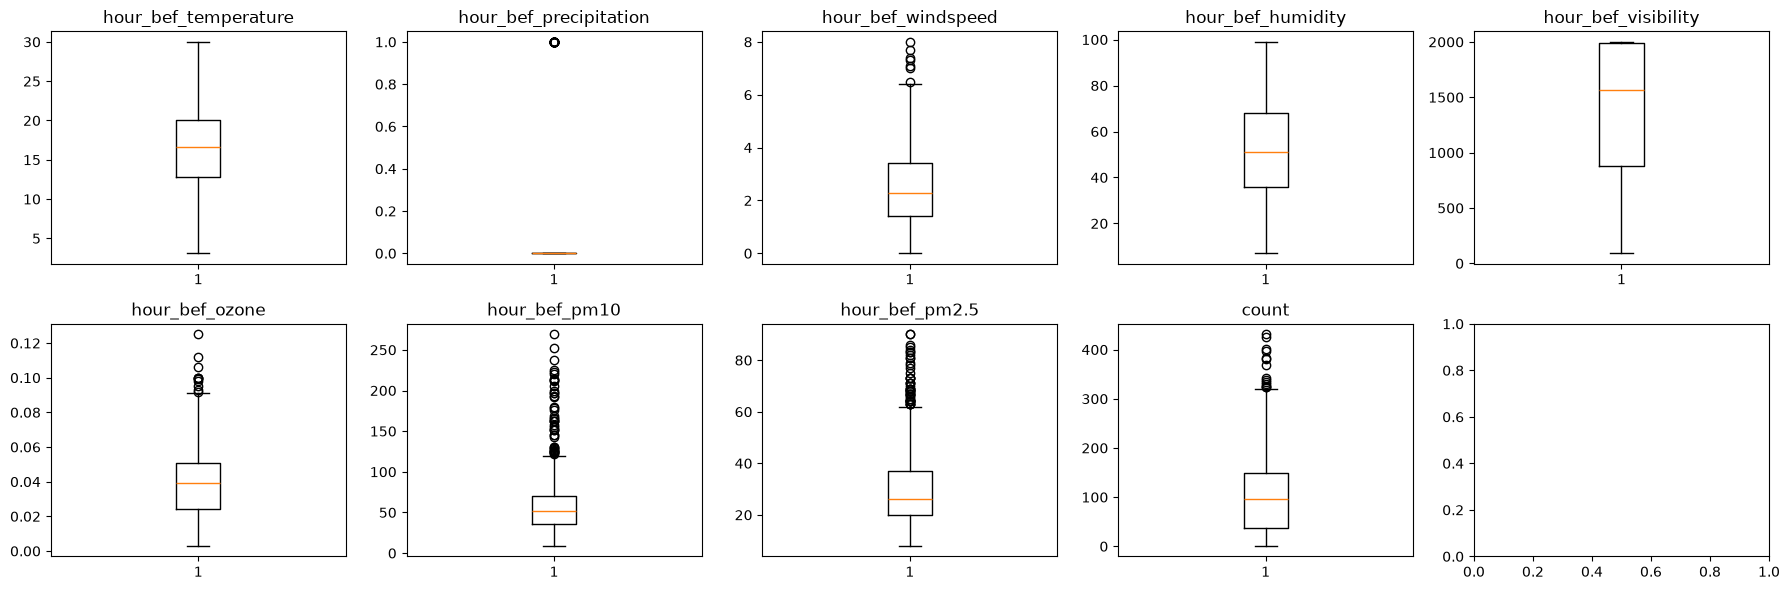

hour_bef_temperature       0
hour_bef_precipitation    38
hour_bef_windspeed         7
hour_bef_humidity          0
hour_bef_visibility        0
hour_bef_ozone            11
hour_bef_pm10             45
hour_bef_pm2.5            48
count                     14
dtype: int64

In [4]:
num_cols = WEATHER_COLS + ['count']
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(train[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.show()

# IQR 기준 이상치 개수 (확인용, 삭제하지 않음)
q1, q3 = train[num_cols].quantile(0.25), train[num_cols].quantile(0.75)
iqr = q3 - q1
((train[num_cols] < q1 - 1.5 * iqr) | (train[num_cols] > q3 + 1.5 * iqr)).sum()

IQR 기준 이상치는 실제 피크 수요나 실제 날씨로 보이므로 삭제하지 않는다. 강수는 0/1 값이라 1이 모두 이상치로 잡히지만 의미 있는 값이다.

## 파생 변수 생성


In [5]:
# 날짜가 없어 요일/주말/계절은 만들 수 없음. 출퇴근 시간대(7~9시, 17~19시) 여부만 추가
for df in (train, holdout, test):
    df['is_peak'] = df['hour'].isin([7, 8, 9, 17, 18, 19]).astype(int)

train.groupby('is_peak')['count'].mean()

is_peak
0     91.689143
1    156.651724
Name: count, dtype: float64

## 범주형 변수 인코딩


In [6]:
# 범주형은 hour 하나뿐이고 트리 모델에는 숫자 그대로 사용한다.
# 선형 모델용 원핫인코딩은 04의 파이프라인 안에서 적용하므로 여기서는 하지 않는다.
train.dtypes

id                          int64
hour                        int64
hour_bef_temperature      float64
hour_bef_precipitation    float64
hour_bef_windspeed        float64
hour_bef_humidity         float64
hour_bef_visibility       float64
hour_bef_ozone            float64
hour_bef_pm10             float64
hour_bef_pm2.5            float64
count                     float64
is_peak                     int64
dtype: object

In [7]:
train.to_csv(f'{PROCESSED_DIR}/train.csv', index=False)
holdout.to_csv(f'{PROCESSED_DIR}/holdout.csv', index=False)
test.to_csv(f'{PROCESSED_DIR}/test.csv', index=False)
print('저장 완료:', train.shape, holdout.shape, test.shape)

저장 완료: (1165, 12) (292, 12) (715, 11)
